# Label-based alignment: Wasserstein and FGW on the organ labels, in 2D

Every mouse section of one cross pair (X1–X6) is aligned to every human section of the pair, in 2D, with the organ labels as the cross cost:
1. **Wasserstein OT on the labels** (`s-none_f-lab_<marginals>`): entropic OT on the label cost alone.
2. **FGW OT on the labels and space** (`s-euc_f-lab_<marginals>`): the label cost plus a GW term on the Euclidean distances within each section, with weight α (`ALPHA`; `s-euc{α}` for α ≠ 0.5).

**Marginals** (`MARGINALS`): `balanced` (`bal`); `semi` (`semi{τ}`: the query side balanced, the target side relaxed by τ, so one solve per direction); `unbalanced` (`ub{τ}`: both sides relaxed by τ).

**Scores**, per section pair and direction (`a_stack`: mouse sections are the queries, the human sections the targets; `b_stack`: the reverse):
- **κ_bal**, the benchmark's metric (0 = chance, 1 = every organ to itself). It is circular here: the cost sees the labels it is scored on, so κ_bal is a ceiling, not a method.
- **gene r, held-out genes**: the mean Pearson r per gene between the query's expression and the target's expression transported through the coupling, minus the same with the target's spots shuffled. The genes are the pair's 500 held-out 1:1 orthologs.
- **gene r, all genes**: the same on every 1:1 ortholog present in all sections of the pair.

Run names follow the doc's `sides_space_features_marginals` (`docs/cross_species_alignment_results.md`, "Run names"). Each section pair here is a `sec2sec` candidate; the pairs that match the query's partner section in laterality L (`partner`) are the doc's `sec2part` runs.

**Before the first run:** the pair features and ortholog counts must exist (`python -m mgw.bench prepare --tier full --pairs <PAIR> --seeds <SEED>`, on the data server). Scores are saved to `<root>/diag/label_alignment/`.

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = os.environ["MKL_NUM_THREADS"] = os.environ["OPENBLAS_NUM_THREADS"] = "8"
os.environ["XLA_PYTHON_CLIENT_ALLOCATOR"] = "platform"   # return JAX's GPU memory after each solve

import sys
sys.path.append("..")

In [2]:
# ============================================================
# Run settings (papermill parameters)
# ============================================================
PAIR = "X4"                      # a cross pair of bench/configs/series.yaml, X1-X6 (a = human, b = mouse)
SEED = 0
MARGINALS = "balanced"           # "balanced" | "semi" (query side balanced, target side TAU) | "unbalanced" (both TAU)
TAU = 0.7                        # marginal relaxation of "semi" and "unbalanced" (1 = balanced)
ALPHA = 0.5                      # weight of the GW term of the FGW run; 1 - ALPHA on the label cost
INNER_TOL = None                 # Sinkhorn threshold; None: bench.yaml's (1e-7); 1e-5 is 7-13x faster (doc, next steps)
CONFIG = "bench.yaml"            # benchmark config (bench/configs)
PIPELINE = "sec2sec_s-euc_f-euc_bal"  # the 2D pipeline whose data and FGW settings are used
ROOT = None                      # benchmark root; None: $MGW_BENCH_DIR or <data dir>/bench

In [3]:
import dataclasses
import time

import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle
from ott.geometry import geometry
from ott.problems.linear import linear_problem
from ott.solvers.linear import sinkhorn

from mgw import crossspecies as cs
from mgw import orthologs
from mgw.bench import config, metrics, prepare, series, solvers
from mgw.bench.pipelines.common import Task

if MARGINALS not in ("balanced", "semi", "unbalanced"):
    raise ValueError(f"MARGINALS must be balanced, semi or unbalanced, not {MARGINALS!r}")
if MARGINALS != "balanced" and not 0 < TAU < 1:
    raise ValueError(f"TAU must lie in (0, 1) for {MARGINALS} marginals, not {TAU}")
MARG = {"balanced": "bal", "semi": f"semi{TAU:g}", "unbalanced": f"ub{TAU:g}"}[MARGINALS]
S_EUC = "s-euc" if ALPHA == 0.5 else f"s-euc{ALPHA:g}"
W_RUN, FGW_RUN = f"s-none_f-lab_{MARG}", f"{S_EUC}_f-lab_{MARG}"
RUNS = (W_RUN, FGW_RUN)
DIRS = ("a_stack", "b_stack")
DIR_NAME = {"a_stack": "mouse → human (a_stack)", "b_stack": "human → mouse (b_stack)"}

root = prepare.bench_root(ROOT)
cfg = config.load(CONFIG)
pair = series.load(cfg.series_path()).pairs[PAIR]
if not prepare.feature_file(root, pair.id, SEED, cfg.feature_hash()).exists():
    raise FileNotFoundError(f"no features for {PAIR}, seed {SEED}; run first: python -m mgw.bench prepare --tier full "
                            f"--pairs {PAIR} --seeds {SEED}")
task = Task(cfg, PIPELINE, pair, SEED, root)
H, Mo = task.data["a"], task.data["b"]           # {name: Section}: human, mouse
secs = {**H, **Mo}
p = task.fgw if INNER_TOL is None else dataclasses.replace(task.fgw, inner_tol=INNER_TOL)
OUT = root / "diag" / "label_alignment"
OUT.mkdir(parents=True, exist_ok=True)
print(f"pair {pair.id}: {pair.a.name} (human, {len(H)} sections) <-> {pair.b.name} (mouse, {len(Mo)} sections), "
      f"{len(H) * len(Mo)} pairs of sections")
print(f"runs {', '.join(RUNS)}\nroot {root}\nsolver settings: {p}")

pair X4: CS18_E1 (human, 6 sections) <-> E12.5_E1 (mouse, 5 sections), 30 pairs of sections
runs s-none_f-lab_bal, s-euc_f-lab_bal
root /nas/lnt/ga79jin/MGW/data/bench
solver settings: FGWParams(alpha=0.5, epsilon=0.005, inner_maxit=3000, outer_maxit=200, inner_tol=1e-07, outer_tol=1e-07)


## The label distribution of each section

The share of each organ in a section's bins at full resolution (the composition that κ_bal scores), on the same organ axis for every section of both embryos. Scored organs are ordered by their mean share; `Other` and `Excluded` (never scored) come last, in grey.

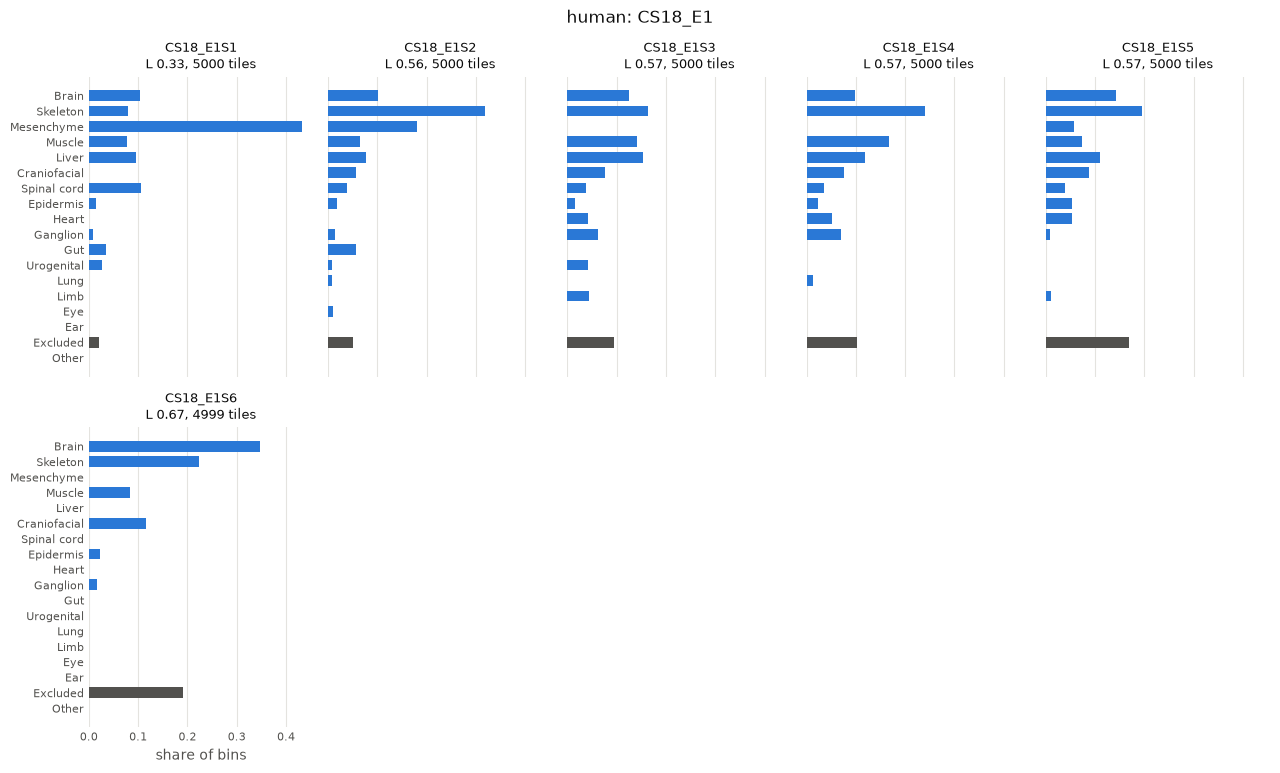

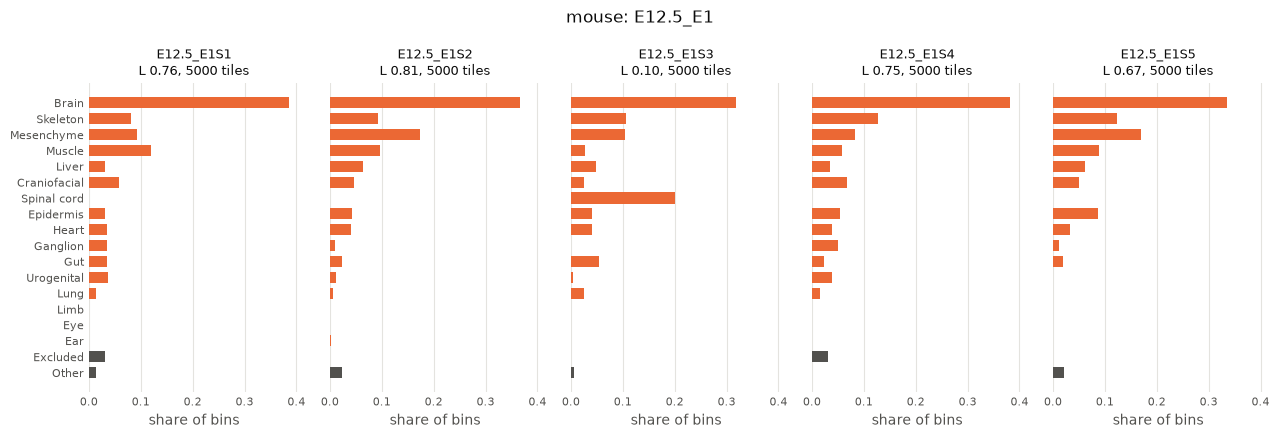

share of bins per organ (%)
              CS18_E1S1  CS18_E1S2  CS18_E1S3  CS18_E1S4  CS18_E1S5  CS18_E1S6  E12.5_E1S1  E12.5_E1S2  E12.5_E1S3  E12.5_E1S4  E12.5_E1S5
Brain              10.3       10.1       12.5        9.8       14.3       34.7        38.6        36.6        31.9        38.2        33.5
Skeleton            8.0       31.9       16.3       24.1       19.6       22.4         8.2         9.3        10.5        12.8        12.3
Mesenchyme         43.3       18.0        0.0        0.0        5.8        0.0         9.3        17.4        10.4         8.3        16.9
Muscle              7.6        6.4       14.1       16.8        7.3        8.4        12.1         9.7         2.8         5.7         8.9
Liver               9.5        7.6       15.3       11.9       10.9        0.0         3.2         6.4         4.8         3.4         6.2
Craniofacial        0.0        5.7        7.7        7.6        8.9       11.5         5.9         4.7         2.5         6.8         5.0

In [4]:
HUMAN, MOUSE = "#2a78d6", "#eb6834"               # categorical slots 1 and 2 (validated pair)
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"

share = pd.DataFrame({n: s.comp.sum(0) / s.comp.sum() for n, s in secs.items()}, index=list(metrics.ORGANS))
scored = lambda o: bool(metrics.SCORED[metrics.ORGAN_INDEX[o]])
seen = share.index[share.max(axis=1) > 0]
organs = (sorted([o for o in seen if scored(o)], key=lambda o: -share.loc[o].mean())
          + [o for o in seen if not scored(o)])
share = share.loc[organs]


def label_histograms(sections, color, species):
    n = len(sections)
    ncol = min(n, 5)
    nrow = -(-n // ncol)
    fig, axes = plt.subplots(nrow, ncol, figsize=(2.3 * ncol + 1.4, 0.19 * len(organs) * nrow + 1.0),
                             sharex=True, sharey=True, squeeze=False)
    y = np.arange(len(organs))
    for ax, (name, s) in zip(axes.flat, sections.items()):
        ax.barh(y, share[name], height=0.7, color=[color if scored(o) else MUTED for o in organs])
        ax.set_title(f"{name}\nL {s.L:.2f}, {s.n} tiles", fontsize=9, color=INK)
        ax.tick_params(colors=MUTED, length=0, labelsize=8)
        ax.grid(axis="x", color=GRID, lw=0.8)
        ax.set_axisbelow(True)
        for sp_ in ax.spines.values():
            sp_.set_visible(False)
    for ax in axes.flat[n:]:
        ax.axis("off")
    axes[0, 0].set_yticks(y, organs)
    axes[0, 0].invert_yaxis()
    for ax in axes[-1]:
        ax.set_xlabel("share of bins", color=MUTED)
    fig.suptitle(f"{species}: {(pair.a if species == 'human' else pair.b).name}", color=INK)
    fig.tight_layout()
    plt.show()


label_histograms(H, HUMAN, "human")
label_histograms(Mo, MOUSE, "mouse")
print("share of bins per organ (%)")
print((100 * share).round(1).to_string())

## The costs and the solvers

- **Labels:** the cost between two spots is 0 for the same organ, 1 for different organs, and 0.5 when either is `Other` or `Excluded` (no evidence either way), averaged over the organ compositions of the two spots.
- **Space:** max-normalized Euclidean distances within each section (centred, RMS radius 1), as in `pipelines/real2d.py`.

`s-none_f-lab` uses entropic OT on the label cost alone (OTT's Sinkhorn); `s-euc_f-lab` the benchmark's FGW solver (`solvers.fgw`), with α the weight of the GW term. Both use the benchmark's ε and uniform masses. A balanced or unbalanced coupling (human × mouse) serves both directions; a semi-balanced one keeps the query side balanced, so each direction has its own solve.

In [5]:
def label_cost(comp_a, comp_b):
    """Organ-label cross cost: 0 same organ, 1 different organs, 0.5 when a side is Other/Excluded."""
    Ka, Kb = metrics.row_normalize(comp_a)[:, metrics.SCORED], metrics.row_normalize(comp_b)[:, metrics.SCORED]
    return 1 - Ka @ Kb.T - 0.5 * (1 - np.outer(Ka.sum(1), Kb.sum(1)))


def ot_linear(M, tau, p, tau_b=None):
    """Entropic OT on the cross cost alone (unbalanced for tau < 1), uniform masses; tau_b: the target side's
    relaxation, if not tau (tau = 1, tau_b < 1: semi-relaxed, the query side balanced)."""
    t0 = time.perf_counter()
    geom = geometry.Geometry(cost_matrix=jnp.asarray(M, dtype=jnp.float32), epsilon=p.epsilon)
    out = sinkhorn.Sinkhorn(max_iterations=p.inner_maxit, threshold=p.inner_tol)(
        linear_problem.LinearProblem(geom, tau_a=tau, tau_b=tau if tau_b is None else tau_b))
    return np.asarray(out.matrix, dtype=np.float64), dict(converged=bool(out.converged),
                                                          seconds=time.perf_counter() - t0)


def taus(direction):
    """(tau_a, tau_b) of the human x mouse coupling that serves `direction`; semi keeps the query side balanced."""
    if MARGINALS == "balanced":
        return 1.0, 1.0
    if MARGINALS == "unbalanced":
        return TAU, TAU
    return (1.0, TAU) if direction == "b_stack" else (TAU, 1.0)


def solve(run, h, m, Ml, tau_a, tau_b):
    """(P, info) of one run on the label cost Ml (rows: the human section h, columns: the mouse section m)."""
    if run == W_RUN:
        return ot_linear(Ml, tau_a, p, tau_b=tau_b)
    return solvers.fgw(None, None, Ml, dataclasses.replace(p, alpha=ALPHA), Ca=D[h], Cb=D[m], tau_a=tau_a,
                       tau_b=tau_b)


D = {n: solvers.dist_norm(task.xy(s)) for n, s in secs.items()}

# the label cost on toy spots: heart, heart, brain, Other
toy = metrics.onehot(["Heart", "Heart", "Brain", "Other"])
assert np.allclose(label_cost(toy, toy), [[0, 0, 1, .5], [0, 0, 1, .5], [1, 1, 0, .5], [.5, .5, .5, .5]])
# Wasserstein: balanced marginals are uniform; semi-relaxed keeps the query's
Mt = np.random.default_rng(0).random((30, 20))
Pt, _ = ot_linear(Mt, 1.0, p)
assert np.allclose(Pt.sum(1), 1 / 30, atol=1e-4) and np.allclose(Pt.sum(0), 1 / 20, atol=1e-4)
Pt, _ = ot_linear(Mt, 1.0, p, tau_b=0.7)
assert np.allclose(Pt.sum(1), 1 / 30, atol=1e-4)
print(f"toy checks passed; marginals {MARGINALS}: (tau_a, tau_b) = {taus('b_stack')} for b_stack (human query), "
      f"{taus('a_stack')} for a_stack (mouse query)")

toy checks passed; marginals balanced: (tau_a, tau_b) = (1.0, 1.0) for b_stack (human query), (1.0, 1.0) for a_stack (mouse query)


## All genes

The log-normalized counts of every section (`prepare.load_counts`, 1:1 orthologs only), with mouse genes renamed to their human orthologs, restricted to the genes present in every section of the pair (without mitochondrial genes, as for the held-out genes). They include the held-out genes and the genes of the embedding; neither enters a label coupling.

In [6]:
ortho = orthologs.load_one2one()
m2h = dict(zip(ortho.mouse, ortho.human))
SH = cfg.section_hash()
missing = [n for n in secs if not prepare.counts_file(root, n, SEED, SH).exists()]
if missing:
    raise FileNotFoundError(f"no ortholog counts for {missing} (they live on the data server); run first: "
                            f"python -m mgw.bench prepare --tier full --pairs {PAIR} --seeds {SEED}")


def ortholog_counts(s):
    """(tiles x genes CSR, human gene symbols) of a section's 1:1 orthologs."""
    a = prepare.load_counts(root, s.name, SEED, SH)
    keep = a.var_names.isin(set(ortho.human) if s.dataset == "HESTA" else set(m2h))
    genes = a.var_names[keep] if s.dataset == "HESTA" else a.var_names[keep].map(m2h)
    return sp.csr_matrix(a.X[:, np.flatnonzero(keep)]), pd.Index(genes)


raw = {n: ortholog_counts(s) for n, s in secs.items()}
GENES = pd.Index(sorted(set.intersection(*(set(g) for _, g in raw.values()))))
GENES = GENES[~GENES.str.upper().str.startswith("MT-")]
G = {n: X[:, g.get_indexer(GENES)].tocsr() for n, (X, g) in raw.items()}
del raw
assert all(G[n].shape[0] == s.n for n, s in secs.items()), "counts and sections disagree on the tiles"
print(f"{len(GENES)} genes in all {len(secs)} sections (held-out genes: {H[next(iter(H))].Y.shape[1]})")


def coexpression_all(Pq, Yq, Yt, seed=SEED, chunk=2000):
    """cs.coexpression in gene chunks: per gene, Pearson r over the query's spots between Yq and Yt transported
    through Pq, and the same with Yt's spots shuffled (the same permutation). Yq, Yt dense float32: the transport is
    a BLAS product (a sparse one runs single-threaded, ~20x slower at these sizes); r is computed in float64."""
    Pn = np.asarray(Pq, dtype=np.float32)
    Pn = Pn / (Pn.sum(1, keepdims=True) + 1e-30)
    perm = np.random.default_rng(seed).permutation(len(Yt))
    r, r0 = [], []
    for j in range(0, Yq.shape[1], chunk):
        cols = slice(j, j + chunk)
        Yqc, Ytc = Yq[:, cols].astype(np.float64), Yt[:, cols]
        r.append(cs.colwise_r(Yqc, (Pn @ Ytc).astype(np.float64)))
        r0.append(cs.colwise_r(Yqc, (Pn @ Ytc[perm]).astype(np.float64)))
    return np.concatenate(r), np.concatenate(r0)


# on the held-out genes, the chunked version is cs.coexpression
qa, tb = H[next(iter(H))], Mo[next(iter(Mo))]
Pt = np.random.default_rng(1).random((qa.n, tb.n))
ra, ra0 = coexpression_all(Pt, qa.Y, tb.Y, chunk=97)
rb, rb0 = cs.coexpression(Pt, qa.Y, tb.Y, seed=SEED)
assert np.allclose(ra, rb, atol=1e-5, equal_nan=True) and np.allclose(ra0, rb0, atol=1e-5, equal_nan=True)
del Pt

13274 genes in all 11 sections (held-out genes: 500)


## Solve and score

Every human section against every mouse section, both runs; each coupling is scored in both directions. `partner`: the target is the query's partner section (the target section closest in laterality L, as in `section_cost_ablation.ipynb`).

In [7]:
def partner(q, targets):
    ok = {n: t.L for n, t in targets.items() if np.isfinite(t.L)}
    return min(ok, key=lambda n: abs(ok[n] - q.L)) if np.isfinite(q.L) and ok else None


PARTNER = {**{("b_stack", q): partner(H[q], Mo) for q in H}, **{("a_stack", q): partner(Mo[q], H) for q in Mo}}

rows = []
for h in H:
    Gh = G[h].toarray()                          # dense for the BLAS products of coexpression_all
    for m in Mo:
        t0, t_solve = time.perf_counter(), 0.0
        Gd = {h: Gh, m: G[m].toarray()}
        Ml = label_cost(H[h].comp, Mo[m].comp)
        for run in RUNS:
            sols = {}
            for d in DIRS:
                tt = taus(d)
                if tt not in sols:
                    ts = time.perf_counter()
                    sols[tt] = solve(run, h, m, Ml, *tt)
                    t_solve += time.perf_counter() - ts
                    if not np.isfinite(sols[tt][0]).all():
                        raise FloatingPointError(f"{run} {tt}: non-finite coupling for {h} x {m}")
                P, info = sols[tt]
                q, t, Pq = (H[h], Mo[m], P) if d == "b_stack" else (Mo[m], H[h], P.T)
                r, r0 = cs.coexpression(Pq, q.Y, t.Y, seed=SEED)
                ra, ra0 = coexpression_all(Pq, Gd[q.name], Gd[t.name])
                rows.append(dict(run=run, direction=d, query=q.name, target=t.name, human=h, mouse=m,
                                 partner=PARTNER[d, q.name] == t.name,
                                 kappa_bal=task.score(d, q, t.name, t.comp, Pq, keep=False)["kappa_bal"],
                                 gene_r_heldout=np.nanmean(r) - np.nanmean(r0), r_heldout=np.nanmean(r),
                                 gene_r_all=np.nanmean(ra) - np.nanmean(ra0), r_all=np.nanmean(ra),
                                 matched=Pq.sum(), converged=bool(info.get("converged")),
                                 seconds=info.get("seconds")))
            del sols
        total = time.perf_counter() - t0
        print(f"{h} ({H[h].n}) x {m} ({Mo[m].n}): {total:.0f} s (solves {t_solve:.0f} s, scoring {total - t_solve:.0f} s)")
    del Gh, Gd
scores = pd.DataFrame(rows)
scores.to_csv(OUT / f"{PAIR}_seed{SEED}_{MARG}.csv", index=False)
print(f"\nscores saved to {OUT / f'{PAIR}_seed{SEED}_{MARG}.csv'}")
if not scores.converged.all():
    print("not converged:", scores.loc[~scores.converged, ["run", "human", "mouse"]].drop_duplicates()
          .to_string(index=False))

CS18_E1S1 (5000) x E12.5_E1S1 (5000): 65 s (solves 55 s, scoring 10 s)
CS18_E1S1 (5000) x E12.5_E1S2 (5000): 88 s (solves 79 s, scoring 9 s)
CS18_E1S1 (5000) x E12.5_E1S3 (5000): 104 s (solves 95 s, scoring 9 s)
CS18_E1S1 (5000) x E12.5_E1S4 (5000): 56 s (solves 46 s, scoring 9 s)
CS18_E1S1 (5000) x E12.5_E1S5 (5000): 151 s (solves 141 s, scoring 10 s)
CS18_E1S2 (5000) x E12.5_E1S1 (5000): 69 s (solves 60 s, scoring 10 s)
CS18_E1S2 (5000) x E12.5_E1S2 (5000): 86 s (solves 76 s, scoring 10 s)
CS18_E1S2 (5000) x E12.5_E1S3 (5000): 56 s (solves 46 s, scoring 10 s)
CS18_E1S2 (5000) x E12.5_E1S4 (5000): 112 s (solves 103 s, scoring 9 s)
CS18_E1S2 (5000) x E12.5_E1S5 (5000): 74 s (solves 65 s, scoring 9 s)
CS18_E1S3 (5000) x E12.5_E1S1 (5000): 64 s (solves 54 s, scoring 9 s)
CS18_E1S3 (5000) x E12.5_E1S2 (5000): 56 s (solves 46 s, scoring 9 s)
CS18_E1S3 (5000) x E12.5_E1S3 (5000): 50 s (solves 41 s, scoring 9 s)
CS18_E1S3 (5000) x E12.5_E1S4 (5000): 69 s (solves 60 s, scoring 9 s)
CS18_E1S3 

## Results

Means over the section pairs of each run and direction: over all pairs, and over the partner pairs only (the doc's `sec2part`). `matched`: the transported mass (1 when balanced).

In [8]:
METRICS = {"kappa_bal": "κ_bal", "gene_r_heldout": "gene r, held-out genes", "gene_r_all": "gene r, all genes"}
COLS = list(METRICS) + ["r_heldout", "r_all", "matched", "seconds"]
summary = pd.concat({"all pairs": scores.groupby(["run", "direction"], sort=False)[COLS].mean(),
                     "partner pairs": scores[scores.partner].groupby(["run", "direction"], sort=False)[COLS].mean()},
                    axis=0, names=["pairs"])
print(summary.round(3).to_string())
print("\nboth directions pooled")
both = pd.concat({"all pairs": scores.groupby("run", sort=False)[list(METRICS)].mean(),
                  "partner pairs": scores[scores.partner].groupby("run", sort=False)[list(METRICS)].mean()}, axis=1)
print(both.round(3).to_string())

                                          kappa_bal  gene_r_heldout  gene_r_all  r_heldout  r_all  matched  seconds
pairs         run              direction                                                                           
all pairs     s-none_f-lab_bal a_stack        0.520           0.294       0.088      0.285  0.086      1.0    3.071
                               b_stack        0.630           0.260       0.070      0.267  0.072      1.0    3.071
              s-euc_f-lab_bal  a_stack        0.521           0.266       0.079      0.261  0.078      1.0   56.823
                               b_stack        0.640           0.240       0.065      0.246  0.066      1.0   56.823
partner pairs s-none_f-lab_bal a_stack        0.389           0.275       0.081      0.276  0.082      1.0    3.352
                               b_stack        0.589           0.264       0.076      0.285  0.078      1.0    3.026
              s-euc_f-lab_bal  a_stack        0.391           0.251     

### Per section pair

One panel per run and direction; rows are the human sections and columns the mouse sections in every panel, so the panels line up. Outlined: the query's partner section. One colour scale per score.

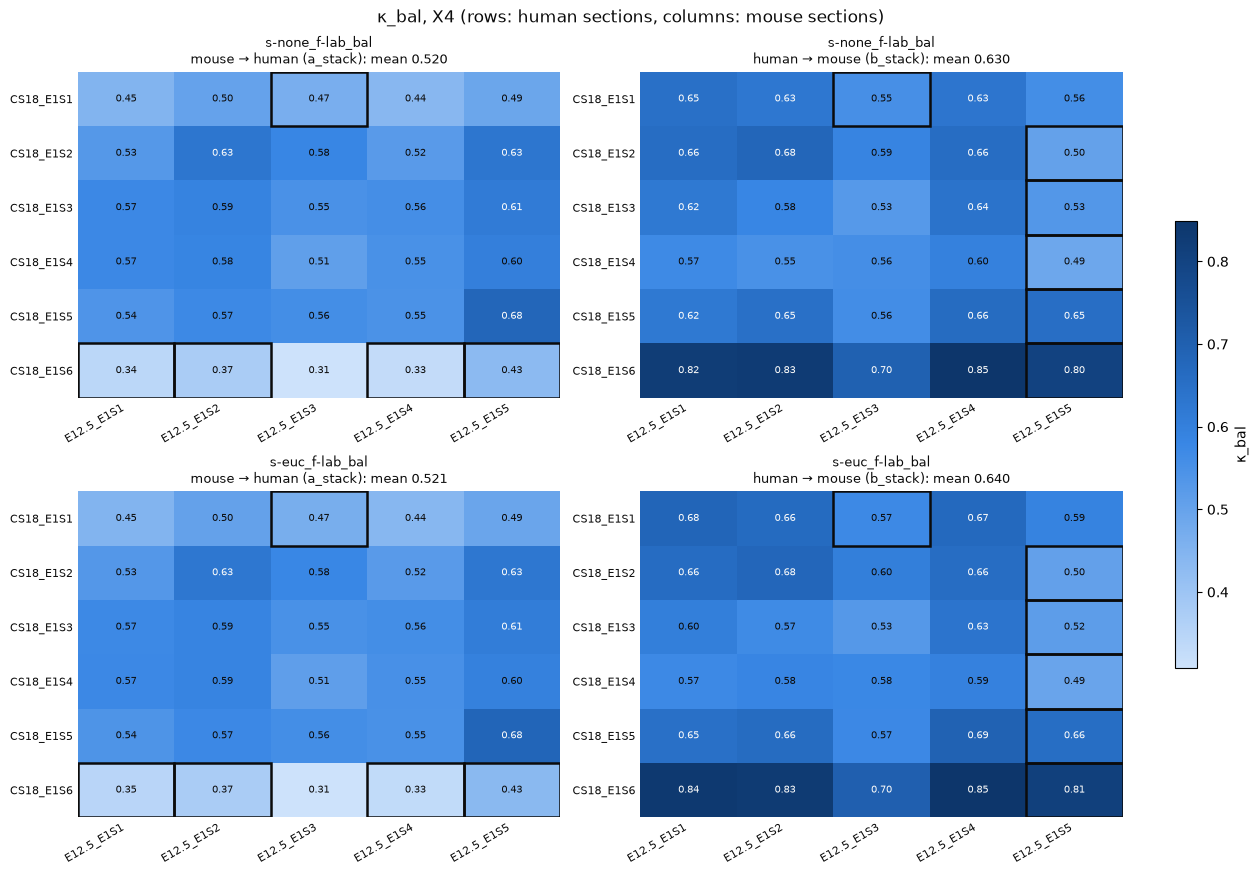

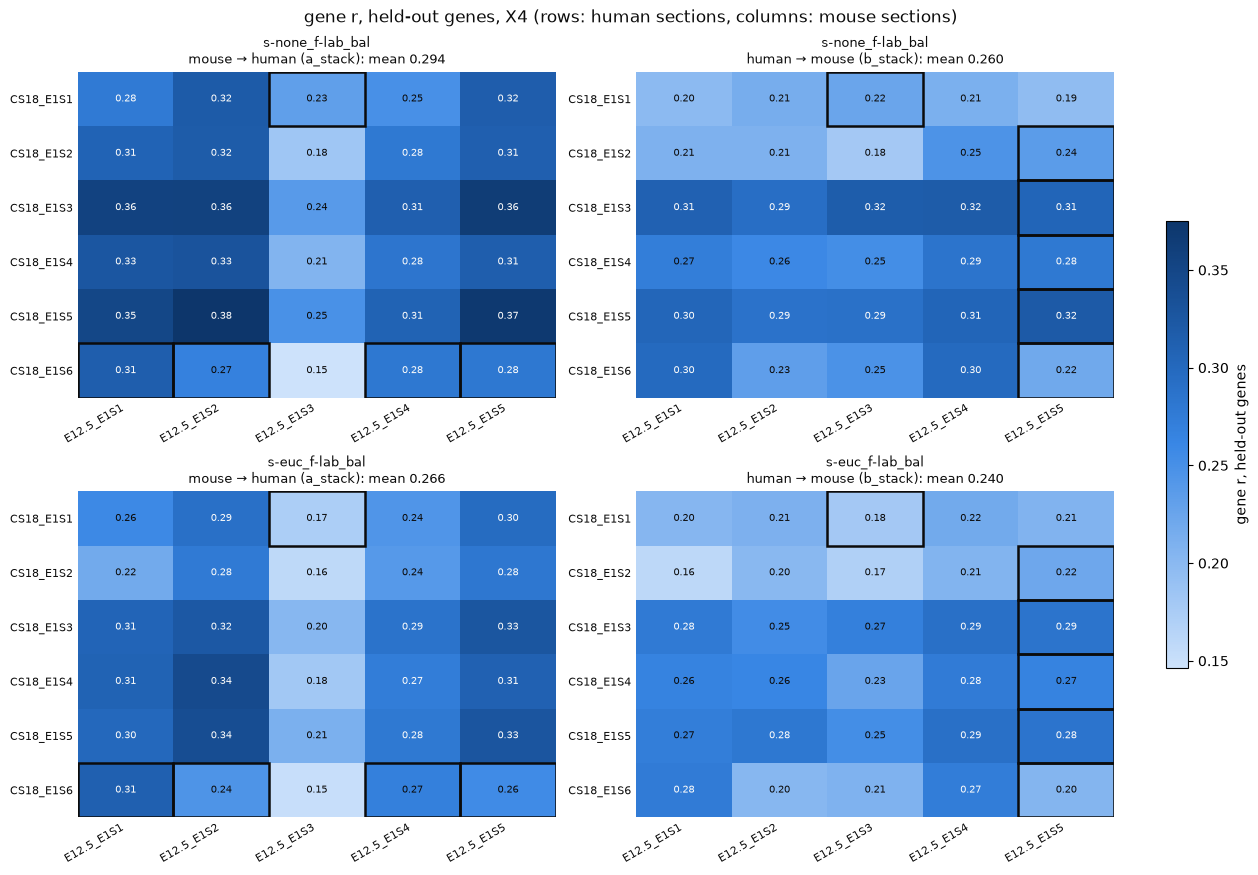

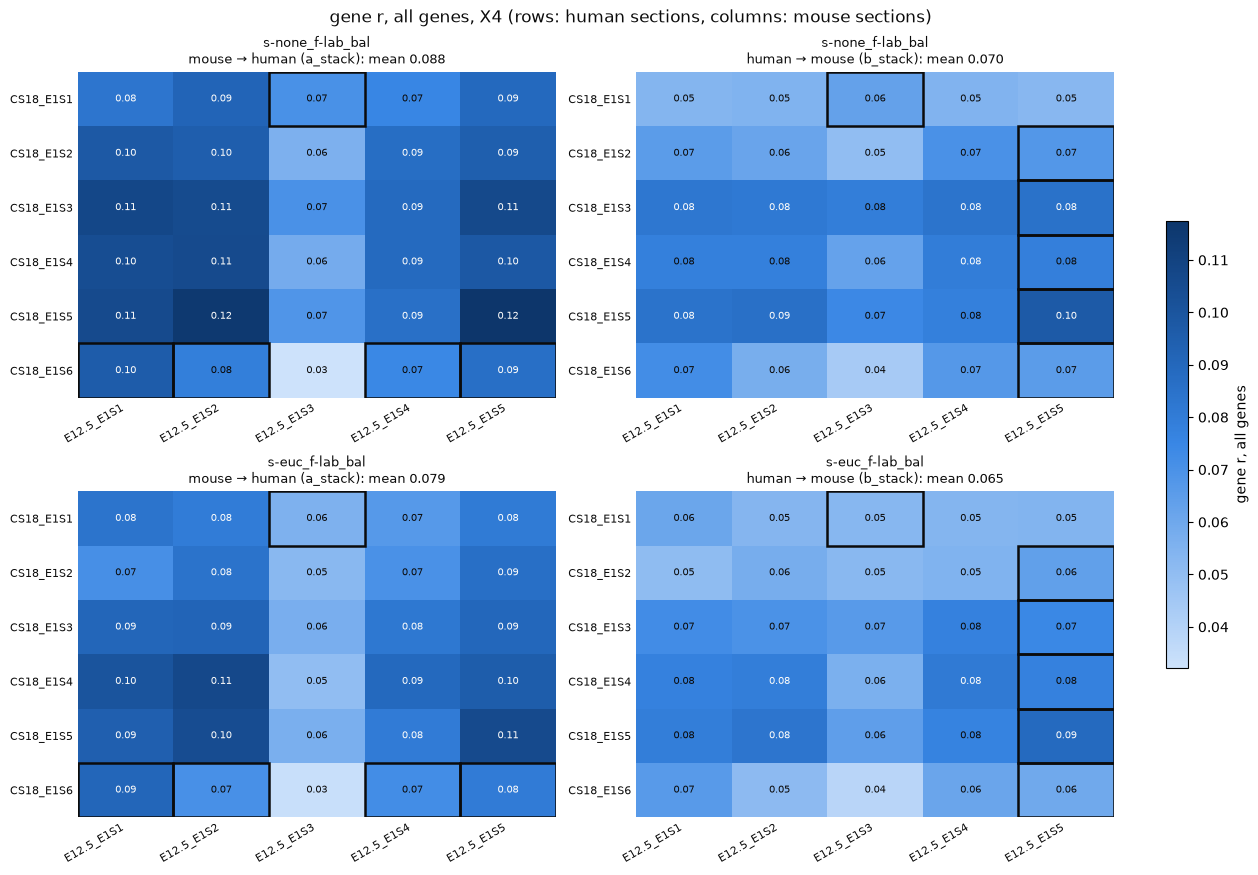

In [9]:
SEQ = LinearSegmentedColormap.from_list("blue", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95",
                                                 "#0d366b"])
SEQ.set_bad(SURFACE)
hs, ms = list(H), list(Mo)

for col, title in METRICS.items():
    v_all = scores[col].to_numpy(dtype=float)
    lo, hi = np.nanmin(v_all), np.nanmax(v_all)
    mid = lo + 0.55 * (hi - lo)
    fig, axes = plt.subplots(len(RUNS), len(DIRS), figsize=(len(DIRS) * (0.85 * len(ms) + 2),
                                                            len(RUNS) * (0.42 * len(hs) + 1.8)), squeeze=False,
                             layout="constrained")
    for i, run in enumerate(RUNS):
        for j, d in enumerate(DIRS):
            ax = axes[i, j]
            s = scores[(scores.run == run) & (scores.direction == d)]
            v = s.pivot_table(index="human", columns="mouse", values=col).reindex(index=hs, columns=ms).to_numpy()
            im = ax.imshow(np.ma.masked_invalid(v), cmap=SEQ, vmin=lo, vmax=hi, aspect="auto")
            for (y, x), val in np.ndenumerate(v):
                if np.isfinite(val):
                    ax.text(x, y, f"{val:.2f}", ha="center", va="center", fontsize=7, color=INK if val < mid else SURFACE)
            for _, r in s[s.partner].iterrows():
                ax.add_patch(Rectangle((ms.index(r.mouse) - 0.5, hs.index(r.human) - 0.5), 1, 1, fill=False, ec=INK,
                                       lw=1.8))
            ax.set_xticks(range(len(ms)), ms, fontsize=8, color=INK, rotation=30, ha="right")
            ax.set_yticks(range(len(hs)), hs, fontsize=8, color=INK)
            ax.tick_params(length=0)
            for sp_ in ax.spines.values():
                sp_.set_visible(False)
            ax.set_title(f"{run}\n{DIR_NAME[d]}: mean {np.nanmean(v):.3f}", fontsize=9, color=INK)
    fig.colorbar(im, ax=axes, shrink=0.6, label=title)
    fig.suptitle(f"{title}, {PAIR} (rows: human sections, columns: mouse sections)", color=INK)
    plt.show()

### Check against the doc

On X4, seed 0, balanced, α = 0.5 and the benchmark's tolerance, the partner pairs are the runs of `docs/cross_species_alignment_results.md`, section 1–2 (first computed in `section_cost_ablation.ipynb`): `sec2part_s-none_f-lab_bal` κ_bal 0.498, `sec2part_s-euc_f-lab_bal` 0.50. Same cost, solver and ε, so the means must agree up to the doc's rounding.

In [10]:
DOC = {"s-none_f-lab_bal": 0.498, "s-euc_f-lab_bal": 0.50}
if (PAIR, SEED, MARGINALS, ALPHA, INNER_TOL) == ("X4", 0, "balanced", 0.5, None):
    for run, ref in DOC.items():
        here = scores[scores.partner & (scores.run == run)].kappa_bal.mean()
        print(f"sec2part_{run}: kappa_bal {here:.3f} here, {ref} in the doc (difference {here - ref:+.3f})")
else:
    print("the doc's values are for X4, seed 0, balanced, alpha 0.5, the default tolerance; the check is skipped")

sec2part_s-none_f-lab_bal: kappa_bal 0.498 here, 0.498 in the doc (difference +0.000)
sec2part_s-euc_f-lab_bal: kappa_bal 0.500 here, 0.5 in the doc (difference +0.000)


### Every row

In [11]:
wide = scores.pivot_table(index=["direction", "query", "target", "partner"], columns="run",
                          values=list(METRICS)).round(3)
print(wide.to_string())

                                             gene_r_all                   gene_r_heldout                        kappa_bal                 
run                                     s-euc_f-lab_bal s-none_f-lab_bal s-euc_f-lab_bal s-none_f-lab_bal s-euc_f-lab_bal s-none_f-lab_bal
direction query      target     partner                                                                                                   
a_stack   E12.5_E1S1 CS18_E1S1  False             0.084            0.083           0.258            0.278           0.448            0.448
                     CS18_E1S2  False             0.071            0.098           0.218            0.307           0.530            0.530
                     CS18_E1S3  False             0.091            0.107           0.305            0.355           0.571            0.573
                     CS18_E1S4  False             0.100            0.104           0.308            0.326           0.574            0.574
                     CS18_E

## How to read the results

- **Wasserstein against FGW:** with a cross cost this close to perfect, the GW term can only pull the coupling away from the labels. If FGW's κ_bal stays close to Wasserstein's, the two sections' geometries agree with their organ layout; where it falls, space and labels disagree (different cut angle, depth or orientation).
- **Partner against other pairs:** how much κ_bal depends on which target section the query is matched to. A pair scores high when its organs exist in both sections; the label histograms show which organs a target lacks.
- **The marginals:** relaxing the target (semi) or both sides (unbalanced) lets mass skip organs the other section lacks; compare `matched` with κ_bal.
- **Transported mass:** under unbalanced marginals `matched` can exceed 1, since the KL-relaxed problem adds mass where the label cost is near 0. κ_bal and gene r normalize each query spot's row of the coupling, so they do not depend on the total.
- **Gene r on held-out against all genes:** no genes enter a label coupling, so the two differ only in the gene set. Gene r favours spread-out couplings (doc, section 6), so read it together with κ_bal, and not across marginals alone.